# AEA Extension: War and Literacy in Liberia and Sierra Leone

In [1]:
# Importing packages (each one once)
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import requests
from matplotlib import animation
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from IPython.display import Video, Image, display
from ipumspy import readers

In [2]:
# Local file locations
wr_ddi_path = "/Users/School/GitHub/HHEI/AEA P&P/Data/idhs_wr.xml"
mr_ddi_path = "/Users/School/GitHub/HHEI/AEA P&P/Data/idhs_mr.xml"
wr_data_path = "/Users/School/GitHub/HHEI/AEA P&P/Data/WR_LBR_SL.dat.gz"
mr_data_path = "/Users/School/GitHub/HHEI/AEA P&P/Data/MR_LBR_SL.dat.gz"

## 1. Load the data

The DDI (`.xml`) is the codebook: variable names, descriptions and value labels. The `.dat.gz` file holds the numbers. `read_microdata` gives you plain numbers, and the labels stay in the DDI object, so we keep both around.

In [3]:
ddi_wr_obj = readers.read_ipums_ddi(wr_ddi_path)
ddi_mr_obj = readers.read_ipums_ddi(mr_ddi_path)

wr_df = readers.read_microdata(ddi_wr_obj, wr_data_path)   # women's recode
mr_df = readers.read_microdata(ddi_mr_obj, mr_data_path)   # men's recode

print("Women's file:", wr_df.shape)
print("Men's file:  ", mr_df.shape)

OSError: File \Users\School\GitHub\HHEI\AEA P&P\Data\idhs_wr.xml does not exist

## 2. Helpers for reading value labels

These three small functions are used throughout. They look codes up **by their label** (e.g. "Always") instead of hard-coding numbers like 95, so the code stays correct if IPUMS codes differ between files.

* `labels_for(ddi, var)` returns `{code: label}` for one variable (an empty dict if the variable is not in that file).
* `codes_matching(ddi, var, pattern)` returns the set of codes whose label matches a regular expression (case-insensitive).
* `SPECIAL_CODES` is the pattern for "no real answer" labels: missing, NIU (not in universe), don't know, and so on.

In [ ]:
def labels_for(ddi, var):
    """{code: label} for one variable, or {} if the variable isn't in this DDI."""
    for v in ddi.data_description:
        if v.name == var:
            return {int(code): str(label) for label, code in v.codes.items()}
    return {}


def codes_matching(ddi, var, pattern):
    """Set of codes whose label matches `pattern` (a case-insensitive regex)."""
    return {code for code, label in labels_for(ddi, var).items()
            if re.search(pattern, label, flags=re.IGNORECASE)}


SPECIAL_CODES = r"missing|\bniu\b|not in universe|don.?t know|refused|no response|inconsistent"

# Quick example: what does LIT2 mean?
labels_for(ddi_wr_obj, "LIT2")

{0: 'Cannot read at all',
 10: 'Reads',
 11: 'Able to read only part of sentence',
 12: 'Able to read whole sentence',
 20: 'Not ascertained (blind, diff. language)',
 21: 'No card with required language',
 22: 'Blind or visually impaired',
 98: 'Missing'}

## 3. Reference tables

Two lookup tables you can filter whenever you need to know what a variable or code means:

* `variables`: one row per variable, with its label and which file it comes from.
* `all_codes`: one row per variable-code pair. Filter it, e.g. `all_codes[all_codes["variable"] == "LIT2"]`.

In [ ]:
variables = pd.DataFrame([
    {"file": file, "variable": v.name, "label": v.label}
    for file, ddi in [("women", ddi_wr_obj), ("men", ddi_mr_obj)]
    for v in ddi.data_description
])

all_codes = pd.DataFrame([
    {"file": file, "variable": v.name, "code": code, "label": label}
    for file, ddi in [("women", ddi_wr_obj), ("men", ddi_mr_obj)]
    for v in ddi.data_description
    for label, code in v.codes.items()
])

all_codes[all_codes["variable"].isin(["LIT2", "LIT2MN"])]

,file,variable,code,label
1371,women,LIT2,0,Cannot read at all
1372,women,LIT2,10,Reads
1373,women,LIT2,11,Able to read only part of sentence
1374,women,LIT2,12,Able to read whole sentence
1375,women,LIT2,20,"Not ascertained (blind, diff. language)"
1376,women,LIT2,21,No card with required language
1377,women,LIT2,22,Blind or visually impaired
1378,women,LIT2,98,Missing
2953,men,LIT2MN,0,Cannot read at all
2954,men,LIT2MN,10,Reads


## 4. Stack the men's and women's files

The two files are separate samples of different people, so we **stack** them (append rows) rather than merging. Many men's variables have an `MN` suffix, so `variable_pairs` gives each concept one shared name.

**Fix vs. the earlier version:** previously, a misspelled or missing men's variable was skipped silently and men just got `NaN`. Now the cell prints any variable it can't find, so you notice. Residence and the person weight were also added to the pairs.

In [ ]:
# harmonized name: (women's variable, men's variable)
variable_pairs = {
    "AGE": ("AGE", "AGEMN"),
    "WEIGHT": ("PERWEIGHT", "PERWEIGHTMN"),
    "RESIDENCE_YEARS": ("RESIDEINTYR", "RESIDEINTYRMN"),
    "EDUCATION_LEVEL": ("EDUCLVL", "EDUCLVLMN"),
    "EDUCATION_YEARS": ("EDYRTOTAL", "EDYRTOTALMN"),
    "LITERACY": ("LIT2", "LIT2MN"),
    "LITERACY_BRIDGE": ("LITBRIG", "LITBRIGMN"),
    "LITERACY_PROGRAM_EVER": ("LITPROGRAMEV", "LITPROGRAMEVMN"),
    "WEALTH_QUINTILE": ("WEALTHQ", "WEALTHQMN"),
    "URBAN_RURAL": ("URBAN", "URBANMN"),
    "WAR_STAYED_HOME": ("MIGRWARSTAY", "MIGRWARSTAYMN"),
    "WAR_RETURNED": ("MIGRWARREL", "MIGRWARRELMN"),
    "WAR_DISPLACED_CAMP": ("MIGRWARCAMP", "MIGRWARCAMPMN"),
    "WAR_DISPLACED_BUSH": ("MIGRWARBUSH", "MIGRWARBUSHMN"),
    "WAR_DISPLACED_ABROAD": ("MIGRWARABROAD", "MIGRWARABROADMN"),
    "WAR_DISPLACED_OTHER": ("MIGRWAROTH", "MIGRWAROTHMN"),
}

# CHECK: every source variable should exist in its file
missing_women = [w for w, m in variable_pairs.values() if w not in wr_df.columns]
missing_men = [m for w, m in variable_pairs.values() if m not in mr_df.columns]
print("Not found in women's file:", missing_women or "none")
print("Not found in men's file:  ", missing_men or "none")


def prepare_recode(data, recode, sex, source_index):
    """Copy each source variable into its harmonized name. Original columns are kept.
    A variable missing from this file becomes an empty column (and shows up in the check above)."""
    prepared = data.copy()
    prepared["RECODE"] = recode
    prepared["SEX"] = sex
    for harmonized_name, source_names in variable_pairs.items():
        source_name = source_names[source_index]
        if source_name in prepared.columns:
            prepared[harmonized_name] = prepared[source_name]
        else:
            prepared[harmonized_name] = pd.Series(pd.NA, index=prepared.index, dtype="Float64")
    return prepared


combined_df = pd.concat(
    [prepare_recode(wr_df, "WR", "Female", 0),
     prepare_recode(mr_df, "MR", "Male", 1)],
    ignore_index=True,
    sort=False,
)

# Country names come from the DDI labels rather than a hand-typed list
country_labels = {**labels_for(ddi_mr_obj, "COUNTRY"), **labels_for(ddi_wr_obj, "COUNTRY")}
combined_df["COUNTRY_NAME"] = combined_df["COUNTRY"].map(country_labels)
print("Combined records:", combined_df.shape)
combined_df["COUNTRY_NAME"].value_counts(dropna=False)

Not found in women's file: none
Not found in men's file:   none
Combined records: (23755, 122)


COUNTRY_NAME
Liberia         13101
Sierra Leone    10654
Name: count, dtype: int64

## 5. Check: which surveys and variables do we actually have?

This is the check that showed only one survey wave per country (Liberia 2007, Sierra Leone 2008). If you want 2013, add those samples to your IPUMS extract and re-download.

The second table shows the share of non-missing values for each harmonized variable by country, year and sex. A `0.0` means that variable doesn't exist for that group, e.g. the war-migration questions may only have been asked in Liberia.

In [ ]:
display(combined_df.groupby(["COUNTRY_NAME", "YEAR", "SEX"]).size().rename("records"))

harmonized = list(variable_pairs)
availability = (
    combined_df[harmonized].notna()
    .groupby([combined_df["COUNTRY_NAME"], combined_df["YEAR"], combined_df["SEX"]])
    .mean()
    .round(2)
    .T            # transpose: variables as rows, groups as columns
)
availability

COUNTRY_NAME  YEAR  SEX   
Liberia       2007  Female    7092
                    Male      6009
Sierra Leone  2008  Female    7374
                    Male      3280
Name: records, dtype: int64

COUNTRY_NAME          Liberia      Sierra Leone     
YEAR                     2007              2008     
SEX                    Female Male       Female Male
AGE                       1.0  1.0          1.0  1.0
WEIGHT                    1.0  1.0          1.0  1.0
RESIDENCE_YEARS           1.0  1.0          1.0  1.0
EDUCATION_LEVEL           1.0  1.0          1.0  1.0
EDUCATION_YEARS           1.0  1.0          1.0  1.0
LITERACY                  1.0  1.0          1.0  1.0
LITERACY_BRIDGE           1.0  1.0          1.0  1.0
LITERACY_PROGRAM_EVER     1.0  1.0          1.0  1.0
WEALTH_QUINTILE           1.0  1.0          1.0  1.0
URBAN_RURAL               1.0  1.0          1.0  1.0
WAR_STAYED_HOME           1.0  1.0          0.0  0.0
WAR_RETURNED              1.0  1.0          0.0  0.0
WAR_DISPLACED_CAMP        1.0  1.0          0.0  0.0
WAR_DISPLACED_BUSH        1.0  1.0          0.0  0.0
WAR_DISPLACED_ABROAD      1.0  1.0          0.0  0.0
WAR_DISPLACED_OTHER       1.0  1.0          0.0  0.0

## 6. Region of residence

`GEO_LR2007_2019` and `GEO_SL2008_2019` are **coarse regions** (groups of counties or districts), not individual counties or districts. This matters later: UCDP events are recorded by county/district, so they must be grouped into these same regions before the two datasets can be joined.

**Fix vs. the earlier version:** region names now come from the DDI instead of a hand-typed dictionary, which had skipped one Sierra Leone code. `.where(condition, other)` keeps the first column where the condition is True and uses the other column elsewhere, so one line picks the right variable for each country.

In [ ]:
is_liberia = combined_df["COUNTRY_NAME"].eq("Liberia")

combined_df["ADMIN_AREA"] = combined_df["GEO_LR2007_2019"].where(is_liberia, combined_df["GEO_SL2008_2019"])

lr_region_labels = {**labels_for(ddi_mr_obj, "GEO_LR2007_2019"), **labels_for(ddi_wr_obj, "GEO_LR2007_2019")}
sl_region_labels = {**labels_for(ddi_mr_obj, "GEO_SL2008_2019"), **labels_for(ddi_wr_obj, "GEO_SL2008_2019")}
combined_df["ADMIN_AREA_NAME"] = combined_df["ADMIN_AREA"].map(lr_region_labels).where(
    is_liberia, combined_df["ADMIN_AREA"].map(sl_region_labels)
)

# CHECK: every record should have a region name; NaN rows here need a look
combined_df.groupby("COUNTRY_NAME")["ADMIN_AREA_NAME"].value_counts(dropna=False)

COUNTRY_NAME  ADMIN_AREA_NAME        
Liberia       South Central, Monrovia    4517
              North Central              2500
              South Eastern B            2364
              North Western              2193
              South Eastern A            1527
Sierra Leone  Northern, North Western    3069
              Southern                   2692
              Eastern                    2577
              Western                    2316
Name: count, dtype: int64

## 7. Turn special codes into missing values

Codes like 98 ("Missing") or 8 ("NIU") are not real values. Left in, a 98 counts as 98 years of schooling. Here they become `NaN`, using each file's own labels.

Only the **harmonized** copies are changed; the original IPUMS columns stay untouched so you can always compare.

Two variables are deliberately *not* in this list:
* `RESIDENCE_YEARS`: code "Always" is a real answer (the person never moved), and it defines our sample. It is handled in step 8.
* `LITERACY`: it has several categories that each need a decision, handled in step 9.

In [ ]:
vars_to_clean = [
    "EDUCATION_LEVEL", "EDUCATION_YEARS", "LITERACY_BRIDGE", "LITERACY_PROGRAM_EVER",
    "WAR_STAYED_HOME", "WAR_RETURNED", "WAR_DISPLACED_CAMP",
    "WAR_DISPLACED_BUSH", "WAR_DISPLACED_ABROAD", "WAR_DISPLACED_OTHER",
]
ddi_by_sex = {"Female": (ddi_wr_obj, 0), "Male": (ddi_mr_obj, 1)}

masked_counts = []
for var in vars_to_clean:
    for sex, (ddi, idx) in ddi_by_sex.items():
        special = codes_matching(ddi, variable_pairs[var][idx], SPECIAL_CODES)
        rows = combined_df["SEX"].eq(sex) & combined_df[var].isin(special)
        combined_df.loc[rows, var] = pd.NA
        masked_counts.append({"variable": var, "sex": sex,
                              "special codes": sorted(special), "set to NaN": int(rows.sum())})

# CHECK: what was masked, and how often
pd.DataFrame(masked_counts)

,variable,sex,special codes,set to NaN
0,EDUCATION_LEVEL,Female,[8],6
1,EDUCATION_LEVEL,Male,[8],4
2,EDUCATION_YEARS,Female,"[96, 97, 98]",32
3,EDUCATION_YEARS,Male,"[96, 97, 98]",31
4,LITERACY_BRIDGE,Female,"[98, 99]",85
5,LITERACY_BRIDGE,Male,"[98, 99]",58
6,LITERACY_PROGRAM_EVER,Female,"[8, 9]",4222
7,LITERACY_PROGRAM_EVER,Male,"[8, 9]",4611
8,WAR_STAYED_HOME,Female,[8],45
9,WAR_STAYED_HOME,Male,[8],28


## 8. Sample restrictions: survey waves and lifelong residents

**Waves.** Kept with a vectorized filter: each comparison makes a True/False column, `&` means *and*, `|` means *or*. This replaces a row-by-row `.apply`, which is slow and harder to read.

**Lifelong residents.** People whose residence answer is "Always" (they never moved), looked up by label separately in each file. This drops about half the sample and is a design choice worth defending in the paper, since people who never moved during a war are a selected group.

`YEARS_IN_PLACE` is a numeric version for movers: the special codes ("Always", "Visitor", missing) become `NaN`.

In [ ]:
allowed_waves = {"Liberia": [2007, 2013], "Sierra Leone": [2008, 2013]}

keep_wave = (
    (combined_df["COUNTRY_NAME"].eq("Liberia") & combined_df["YEAR"].isin(allowed_waves["Liberia"]))
    | (combined_df["COUNTRY_NAME"].eq("Sierra Leone") & combined_df["YEAR"].isin(allowed_waves["Sierra Leone"]))
)
sample = combined_df.loc[keep_wave].copy()

always_codes = {
    "Female": codes_matching(ddi_wr_obj, "RESIDEINTYR", r"\balways\b"),
    "Male": codes_matching(ddi_mr_obj, "RESIDEINTYRMN", r"\balways\b"),
}
print("'Always' codes found:", always_codes)
if not all(always_codes.values()):
    raise ValueError("Could not find the 'Always' residence code in one of the DDIs.")

sample["LIFELONG_RESIDENT"] = False
for sex, codes in always_codes.items():          # a loop over 2 sexes, not over rows
    rows = sample["SEX"].eq(sex)
    sample.loc[rows, "LIFELONG_RESIDENT"] = sample.loc[rows, "RESIDENCE_YEARS"].isin(codes)

residence_special = {
    "Female": codes_matching(ddi_wr_obj, "RESIDEINTYR", r"always|visitor|" + SPECIAL_CODES),
    "Male": codes_matching(ddi_mr_obj, "RESIDEINTYRMN", r"always|visitor|" + SPECIAL_CODES),
}
sample["YEARS_IN_PLACE"] = sample["RESIDENCE_YEARS"]
for sex, codes in residence_special.items():
    rows = sample["SEX"].eq(sex) & sample["RESIDENCE_YEARS"].isin(codes)
    sample.loc[rows, "YEARS_IN_PLACE"] = pd.NA

# CHECK
sample.groupby(["COUNTRY_NAME", "SEX"])["LIFELONG_RESIDENT"].mean().round(3)

'Always' codes found: {'Female': {95}, 'Male': {94}}


COUNTRY_NAME  SEX   
Liberia       Female    0.548
              Male      0.495
Sierra Leone  Female    0.452
              Male      0.561
Name: LIFELONG_RESIDENT, dtype: float64

## 9. Literacy

Every literacy code gets an explicit category instead of "whole sentence = 1, everything else = 0":

| category | meaning | `LITERACY_STRICT` | `LITERACY_BROAD` |
|---|---|---|---|
| whole | reads a whole sentence | 1 | 1 |
| part | reads part of a sentence | 0 | 1 |
| cannot | cannot read at all | 0 | 0 |
| exclude | blind/visually impaired, or no card in the required language: literacy wasn't measured | NaN | NaN |
| missing | missing, NIU, don't know | NaN | NaN |

`LITERACY_STRICT` is your original definition. `LITERACY_BROAD` matches the DHS standard indicator and works as a robustness check.

**Safety check:** if a code in the data doesn't match any rule, the cell stops with an error listing the code and its label, so a new or unexpected code can never be silently counted as illiterate. If that happens, read the label and add a rule for it.

In [ ]:
# Rules are tried in order; the first match wins.
literacy_rules = [
    ("missing", SPECIAL_CODES),
    ("exclude", r"blind|visual"),
    ("exclude", r"card|language"),
    ("whole", r"whole sentence"),
    ("part", r"part"),
    ("cannot", r"cannot|not able|unable"),
]


def classify_codes(ddi, var, rules):
    """{code: category} using the first rule whose pattern matches the code's label."""
    result = {}
    for code, label in labels_for(ddi, var).items():
        for category, pattern in rules:
            if re.search(pattern, label, flags=re.IGNORECASE):
                result[code] = category
                break
    return result


literacy_categories = {
    "Female": classify_codes(ddi_wr_obj, "LIT2", literacy_rules),
    "Male": classify_codes(ddi_mr_obj, "LIT2MN", literacy_rules),
}

sample["LIT_CATEGORY"] = pd.Series(pd.NA, index=sample.index, dtype="string")
for sex, mapping in literacy_categories.items():
    rows = sample["SEX"].eq(sex)
    sample.loc[rows, "LIT_CATEGORY"] = sample.loc[rows, "LITERACY"].map(mapping)

# SAFETY CHECK: stop if any observed code wasn't classified
unclassified = sample.loc[sample["LITERACY"].notna() & sample["LIT_CATEGORY"].isna(), ["SEX", "LITERACY"]]
if len(unclassified):
    details = unclassified.value_counts().reset_index()
    details["label"] = [labels_for(ddi_by_sex[s][0], variable_pairs["LITERACY"][ddi_by_sex[s][1]]).get(c)
                        for s, c in zip(details["SEX"], details["LITERACY"])]
    raise ValueError(f"Unclassified literacy codes; add a rule for them:\n{details}")

sample["LITERACY_STRICT"] = sample["LIT_CATEGORY"].map({"whole": 1, "part": 0, "cannot": 0}).astype("Float64")
sample["LITERACY_BROAD"] = sample["LIT_CATEGORY"].map({"whole": 1, "part": 1, "cannot": 0}).astype("Float64")

# CHECK: how each code was classified, with counts
check = sample.groupby(["SEX", "LITERACY", "LIT_CATEGORY"], dropna=False).size().rename("n").reset_index()
check["label"] = [labels_for(ddi_by_sex[s][0], variable_pairs["LITERACY"][ddi_by_sex[s][1]]).get(c)
                  for s, c in zip(check["SEX"], check["LITERACY"])]
check

,SEX,LITERACY,LIT_CATEGORY,n,label
0,Female,0,cannot,9361,Cannot read at all
1,Female,11,part,1086,Able to read only part of sentence
2,Female,12,whole,3895,Able to read whole sentence
3,Female,21,exclude,29,No card with required language
4,Female,22,exclude,10,Blind or visually impaired
5,Female,98,missing,85,Missing
6,Male,0,cannot,3447,Cannot read at all
7,Male,11,part,900,Able to read only parts of sentence
8,Male,12,whole,4843,Able to read whole sentence
9,Male,21,exclude,32,No card with required language


## 10. Build the analysis sample and check it

The analysis sample keeps lifelong residents with a measured literacy answer.

The attrition table shows *why* records were dropped. The education-by-literacy table is the check from our discussion: people with secondary education or more should almost all be literate. If they all have one odd code, they were probably never tested.

In [ ]:
has_literacy = sample["LITERACY_STRICT"].notna()
lifelong = sample["LIFELONG_RESIDENT"]

attrition = pd.DataFrame({
    "Country": sample["COUNTRY_NAME"],
    "Wave-filtered records": 1,
    "Not lifelong resident only": ~lifelong & has_literacy,
    "No literacy measure only": lifelong & ~has_literacy,
    "Fail both filters": ~lifelong & ~has_literacy,
    "Retained": lifelong & has_literacy,
}).groupby("Country").sum()      # True counts as 1, so summing counts the rows
display(attrition)

postwar_clean_df = sample.loc[lifelong & has_literacy].copy()
liberia_clean_df = postwar_clean_df.loc[postwar_clean_df["COUNTRY_NAME"].eq("Liberia")].copy()
sierra_leone_clean_df = postwar_clean_df.loc[postwar_clean_df["COUNTRY_NAME"].eq("Sierra Leone")].copy()

# CHECK: education level vs. literacy category
edu_labels = {**labels_for(ddi_mr_obj, "EDUCLVLMN"), **labels_for(ddi_wr_obj, "EDUCLVL")}
pd.crosstab(postwar_clean_df["EDUCATION_LEVEL"].map(edu_labels), postwar_clean_df["LIT_CATEGORY"])

,Wave-filtered records,Not lifelong resident only,No literacy measure only,Fail both filters,Retained
Country,,,,,
Liberia,13101,6161,46,80,6814
Sierra Leone,10654,5436,55,42,5121


LIT_CATEGORY,cannot,part,whole
EDUCATION_LEVEL,,,
Higher,0,0,272
No education,5594,15,5
Primary,1523,1040,543
Secondary,0,0,2942


## 11. Weighted literacy rates

DHS samples aren't self-weighting, so rates use the person weight. A weighted share is `sum(weight × literate) / sum(weight)`, computed per group. This version is vectorized: no loop, one `groupby`.

Compare strict and broad side by side: a big gap means your choice of definition matters, which is worth reporting.

In [ ]:
def weighted_share(df, col, by):
    """Weighted mean of a 0/1 column within each group."""
    d = df.loc[df[col].notna() & df["WEIGHT"].notna()]
    sums = d.assign(weighted=d[col] * d["WEIGHT"]).groupby(by)[["weighted", "WEIGHT"]].sum()
    return sums["weighted"] / sums["WEIGHT"]


groups = ["COUNTRY_NAME", "YEAR", "SEX"]
literacy_rates = pd.DataFrame({
    "strict (whole sentence)": weighted_share(postwar_clean_df, "LITERACY_STRICT", groups),
    "broad (part or whole)": weighted_share(postwar_clean_df, "LITERACY_BROAD", groups),
    "unweighted strict": postwar_clean_df.groupby(groups)["LITERACY_STRICT"].mean(),
    "n": postwar_clean_df.groupby(groups).size(),
}).round(3)
literacy_rates

strict (whole sentence)  broad (part or whole)  \
COUNTRY_NAME YEAR SEX                                                      
Liberia      2007 Female                    0.277                  0.395   
                  Male                      0.542                  0.669   
Sierra Leone 2008 Female                    0.154                    0.2   
                  Male                      0.281                  0.338   

                          unweighted strict     n  
COUNTRY_NAME YEAR SEX                              
Liberia      2007 Female              0.257  3865  
                  Male                0.547  2949  
Sierra Leone 2008 Female               0.18  3308  
                  Male                0.308  1813

# Uppsala Conflict Data Program

**Note for the merge:** UCDP's `adm_1` is the county in Liberia, and `adm_2` the district in Sierra Leone. The DHS regions from step 6 are *groups* of these, so the next step is a lookup table assigning each county/district to its DHS region, then summing events and deaths by region.

In [ ]:
ucpd_path = "/Users/School/GitHub/HHEI/Data/Public_UCDP_GED_Global.csv"
data_dir = "/Users/School/GitHub/HHEI/Data"

# low_memory=False reads the file in one pass, which fixes the mixed-type warning
ucpd = pd.read_csv(ucpd_path, low_memory=False)

In [ ]:
violence_labels = {1: "State-based", 2: "Non-state", 3: "One-sided"}

ged = ucpd[ucpd["country"].isin(["Liberia", "Sierra Leone"])].copy()
ged["violence_type"] = ged["type_of_violence"].map(violence_labels)

# Liberia: adm_1 = county. Sierra Leone: adm_1 = province, adm_2 = district.
ged["admin_unit"] = ged["adm_1"].where(ged["country"].eq("Liberia"), ged["adm_2"])
ged["admin_unit"] = ged["admin_unit"].fillna("Unknown / not geocoded")

# CHECK: the units you'll need to map onto DHS regions
ged.groupby("country")["admin_unit"].value_counts()

country       admin_unit                 
Liberia       Montserrado county             115
              Lofa county                     94
              Nimba county                    50
              Bong county                     42
              Bomi county                     40
              Grand Cape Mount county         39
              River Cess county               31
              Grand Bassa county              28
              Grand Gedeh county              28
              Sinoe county                    22
              Unknown / not geocoded          21
              Maryland county                 13
              Margibi county                  11
              Grand Kru county                 9
              River Gee county                 5
              Gbarpolu county                  3
Sierra Leone  Kono district                  221
              Kenema district                215
              Port Loko district             157
              Kailahun dist

In [ ]:
country_summary = (
    ged.groupby(["country", "violence_type"])
    .agg(
        events=("id", "count"),
        deaths_best=("best", "sum"),
        deaths_low=("low", "sum"),
        deaths_high=("high", "sum"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .reset_index()
)
country_summary

,country,violence_type,events,deaths_best,deaths_low,deaths_high,first_year,last_year
0,Liberia,Non-state,60,3026,1372,5703,1990,1996
1,Liberia,One-sided,371,17160,17160,18874,1989,2024
2,Liberia,State-based,120,3048,2947,3267,1989,2003
3,Sierra Leone,Non-state,12,81,81,81,1991,1996
4,Sierra Leone,One-sided,852,8893,8892,14021,1991,2021
5,Sierra Leone,State-based,633,11470,11466,18425,1991,2001


## Conflict-event animation

Unchanged from your version. It is slow to render, so you may want to skip it while working on the cleaning. (The `KeyboardInterrupt` you saw earlier came from running it in debug mode with a breakpoint, not from a bug.)

KeyboardInterrupt: 

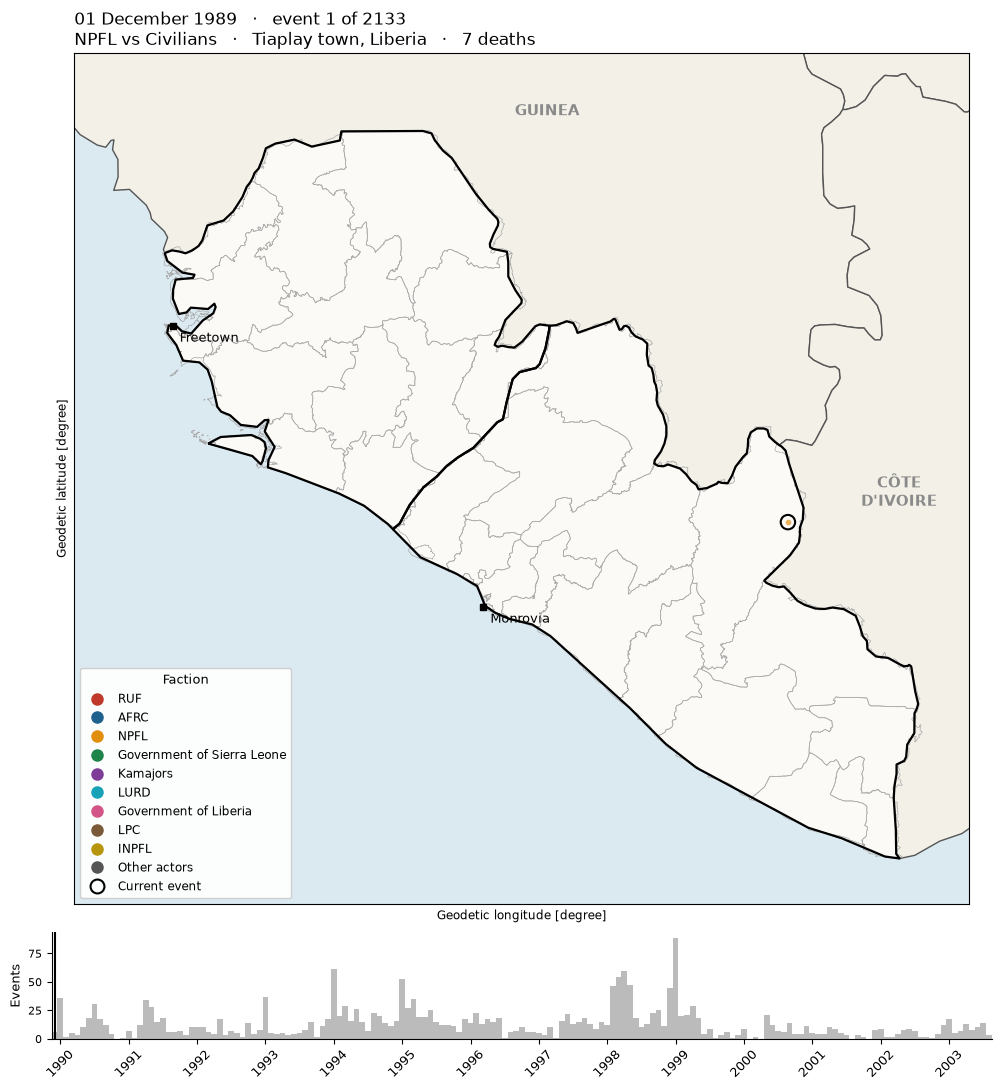

In [ ]:
# Larger, higher-resolution version of the conflict-event animation.
# Assumes the same imports and `ucpd` DataFrame as the original notebook
# (pandas as pd, numpy as np, geopandas as gpd, matplotlib.pyplot as plt,
#  matplotlib.animation as animation, to_rgba, Line2D, requests, os, Video, Image).

# ---- settings -------------------------------------------------------------
data_dir = "/Users/School/GitHub/HHEI/Data"
start_date, end_date = "1989-12-01", "2003-08-31"   # outer limits; frames run first event -> last event
west, east, south, north = -14.0, -7.0, 4.0, 10.6
region = ["Liberia", "Sierra Leone", "Guinea", "Ivory Coast"]
n_factions = 9        # most active factions get their own colour
step = 1              # events added per frame (1 = battle by battle; raise to speed up)
fps = 12              # frames per second

# Size / resolution (new). 10 x 11.2 in at 150 dpi = 1500 x 1680 px video:
# sharp when zoomed, and both dimensions are even, which the mp4 encoder requires.
fig_w, fig_h = 10, 11.2
video_dpi = 150
gif_dpi = 90
display_width = 900   # on-screen width in the notebook; fits a laptop screen

# ---- events, in chronological order ---------------------------------------
ev = ucpd.copy()
ev["date"] = pd.to_datetime(ev["date_start"], errors="coerce")
ev = ev[
    ev["date"].between(start_date, end_date)
    & ev["country"].isin(region)
    & ev["longitude"].between(west, east)
    & ev["latitude"].between(south, north)
].sort_values(["date", "id"]).reset_index(drop=True)

def faction(row):
    """Armed group behind the event: the first side that is not a government or civilians."""
    for side in (row["side_a"], row["side_b"]):
        s = str(side)
        if not s.startswith("Government of") and s != "Civilians":
            return s
    return str(row["side_a"])

ev["faction"] = ev.apply(faction, axis=1)
top = ev["faction"].value_counts().head(n_factions).index.tolist()
palette = ["#c0392b", "#1f618d", "#e08e0b", "#1e8449", "#7d3c98",
           "#17a2b8", "#d35487", "#7b5a3a", "#b7950b", "#34495e"]
fcolors = {f: palette[i % len(palette)] for i, f in enumerate(top)}

n = len(ev)
xy = ev[["longitude", "latitude"]].to_numpy()
rgba = np.array([to_rgba(fcolors.get(f, "#555555"), 0.65) for f in ev["faction"]])
# Slightly smaller base size so overlapping events stay distinguishable on the larger map
sizes = (10 + 3.5 * np.sqrt(ev["best"].clip(lower=0))).to_numpy()

months = pd.period_range(ev["date"].min(), ev["date"].max(), freq="M")
ev["mi"] = (ev["date"].dt.year - months[0].year) * 12 + ev["date"].dt.month - months[0].month
monthly = ev.groupby("mi").size().reindex(range(len(months)), fill_value=0)

# ---- borders --------------------------------------------------------------
def boundaries(iso, level):
    """geoBoundaries admin units, downloaded once and cached in data_dir."""
    path = os.path.join(data_dir, f"geoBoundaries-{iso}-{level}.geojson")
    if not os.path.exists(path):
        try:
            meta = requests.get(
                f"https://www.geoboundaries.org/api/current/gbOpen/{iso}/{level}/", timeout=60
            ).json()
            url = meta["gjDownloadURL"]
        except Exception:
            url = ("https://github.com/wmgeolab/geoBoundaries/raw/main/releaseData/"
                   f"gbOpen/{iso}/{level}/geoBoundaries-{iso}-{level}.geojson")
        r = requests.get(url, timeout=120)
        r.raise_for_status()
        with open(path, "wb") as f:
            f.write(r.content)
    return gpd.read_file(path)

world = gpd.read_file(os.path.join(data_dir, "ne_50m_admin_0_countries.zip"))
focus = world[world["ADMIN"].isin(["Liberia", "Sierra Leone"])]
admin = pd.concat([boundaries("LBR", "ADM1"), boundaries("SLE", "ADM2")])

# ---- figure ---------------------------------------------------------------
fig, (ax, tl) = plt.subplots(
    2, 1, figsize=(fig_w, fig_h), gridspec_kw={"height_ratios": [8, 1], "hspace": 0.06}
)
fig.subplots_adjust(left=0.03, right=0.97, top=0.93, bottom=0.05)   # use the extra space for the map

ax.set_facecolor("#dbe9f1")
world.plot(ax=ax, color="#f3f0e8", edgecolor="#555555", linewidth=1.0)
focus.plot(ax=ax, color="#fbfaf6", edgecolor="none")
admin.boundary.plot(ax=ax, color="#a9a9a9", linewidth=0.5, zorder=2)
focus.boundary.plot(ax=ax, color="black", linewidth=1.6, zorder=2.5)
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_xticks([]); ax.set_yticks([])

for name, x, y in [("GUINEA", -10.3, 10.15), ("CÔTE\nD'IVOIRE", -7.55, 7.2)]:
    ax.text(x, y, name, ha="center", va="center", fontsize=11,
            color="#8a8a8a", fontweight="bold", zorder=1)
for name, x, y in [("Freetown", -13.23, 8.48), ("Monrovia", -10.80, 6.30)]:
    ax.plot(x, y, marker="s", ms=5, color="black", zorder=6)
    ax.annotate(name, (x, y), xytext=(5, -11), textcoords="offset points", fontsize=9, zorder=6)

# Thin white outline on each dot separates events that sit on top of each other
dots = ax.scatter([], [], s=[], edgecolors="white", linewidths=0.3, zorder=3)  # all events so far
ring = ax.scatter([], [], s=[], facecolors="none", edgecolors="black",         # the newest event(s)
                  linewidths=1.5, zorder=5)
title = ax.set_title("", fontsize=12, loc="left")

handles = [Line2D([], [], marker="o", ls="", color=c, ms=8, label=f) for f, c in fcolors.items()]
handles += [
    Line2D([], [], marker="o", ls="", color="#555555", ms=8, label="Other actors"),
    Line2D([], [], marker="o", ls="", mfc="none", mec="black", mew=1.5, ms=10, label="Current event"),
]
ax.legend(handles=handles, loc="lower left", frameon=True, framealpha=0.92,
          fontsize=8.5, title="Faction", title_fontsize=9.5)

tl.bar(range(len(months)), monthly.values, color="#bbbbbb", width=1.0)
marker = tl.axvline(0, color="black", linewidth=1.5)
jan = [i for i, m in enumerate(months) if m.month == 1]
tl.set_xticks(jan)
tl.set_xticklabels([months[i].year for i in jan], fontsize=9, rotation=45)
tl.set_xlim(-0.5, len(months) - 0.5)
tl.set_ylabel("Events", fontsize=9)
tl.tick_params(axis="y", labelsize=8)
for s in ["top", "right"]:
    tl.spines[s].set_visible(False)

n_steps = int(np.ceil(n / step))
hold = fps * 3                                   # pause on the final map for 3 seconds

def update(k):
    i = min((k + 1) * step, n)                   # number of events shown so far
    j = max(i - step, 0)                         # start of the newest batch
    dots.set_offsets(xy[:i])
    dots.set_sizes(sizes[:i])
    dots.set_facecolors(rgba[:i])
    ring.set_offsets(xy[j:i])
    ring.set_sizes(sizes[j:i] * 3 + 50)
    row = ev.iloc[i - 1]
    marker.set_xdata([row["mi"], row["mi"]])
    title.set_text(
        f"{row['date'].strftime('%d %B %Y')}   ·   event {i} of {n}\n"
        f"{row['side_a']} vs {row['side_b']}   ·   "
        f"{row.get('where_coordinates', '')}, {row['country']}   ·   {int(row['best'])} deaths"
    )
    return dots, ring, marker, title

anim = animation.FuncAnimation(fig, update, frames=n_steps + hold, interval=1000 / fps)

# ---- save and show --------------------------------------------------------
out = os.path.join(data_dir, "conflict_events_large")
if animation.writers.is_available("ffmpeg"):
    anim.save(out + ".mp4", writer="ffmpeg", fps=fps, dpi=video_dpi,
              extra_args=["-pix_fmt", "yuv420p"])   # plays in browsers and QuickTime
    shown = Video(out + ".mp4", embed=True, html_attributes="controls loop", width=display_width)
else:
    anim.save(out + ".gif", writer="pillow", fps=fps, dpi=gif_dpi)
    shown = Image(filename=out + ".gif", width=display_width)
plt.close(fig)
print(f"{n} events, {ev['date'].min():%d %b %Y} to {ev['date'].max():%d %b %Y}")
shown